<a href="https://colab.research.google.com/github/HaniaRan/infografia-intercambio-uk/blob/main/PAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##**Figura 1**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# 1\. Definir lista de muestras a graficar (de abajo hacia arriba)
# Puedes agregar o quitar archivos CSV según las muestras que quieras mostrar
samples = [
    ('A_M1.CSV', 'Control (M1)', 'black'),
    ('A_M10.CSV', 'M10 (Sin Vacío, 130°C)', '#d95f02'),
    ('A_M6.CSV', 'M6 (240 mbar, 100°C)', '#7570b3'),
    ('A_M4.CSV', 'M4 (240 mbar, 110°C)', '#e7298a'),
    ('A_M5.CSV', 'M5 (600 mbar, 110°C)', '#66a61e'),
    ('A_M9.CSV', 'M9 (600 mbar, 110°C, Óptima)', '#1b9e77')
]

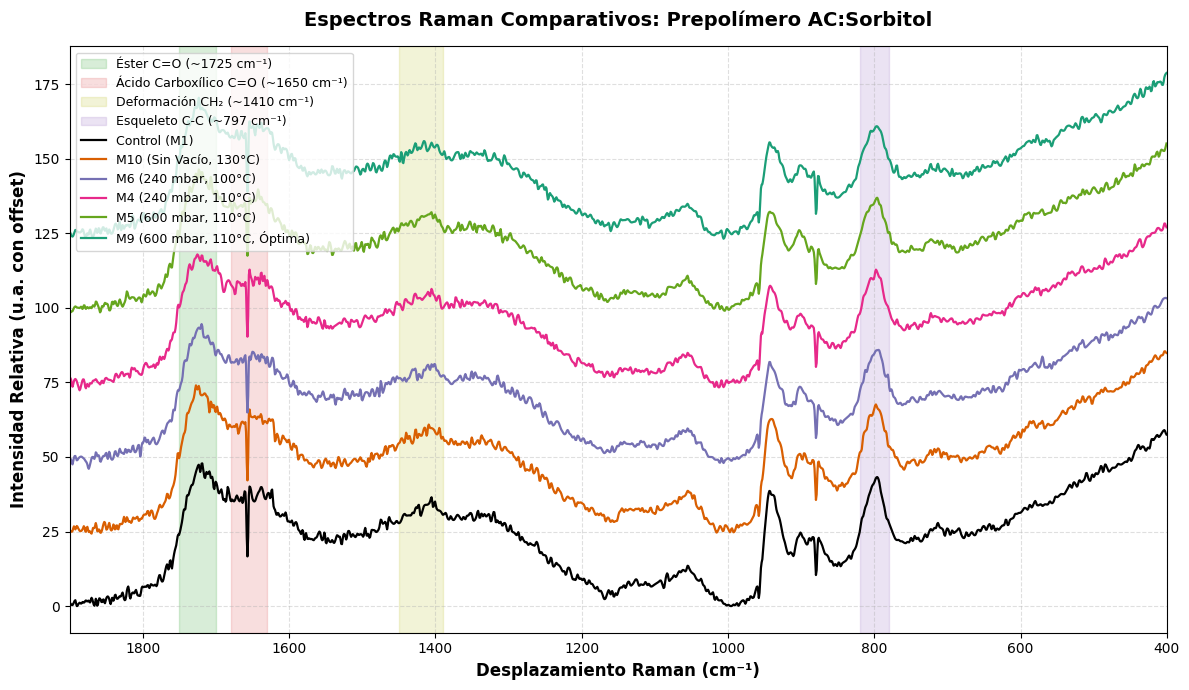

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))

# 2\. Sombras verticales para las bandas de interés espectral
ax.axvspan(1700, 1750, color='#2ca02c', alpha=0.18, label='Éster C=O (~1725 cm⁻¹)')
ax.axvspan(1630, 1680, color='#d62728', alpha=0.15, label='Ácido Carboxílico C=O (~1650 cm⁻¹)')
ax.axvspan(1390, 1450, color='#bcbd22', alpha=0.18, label='Deformación CH₂ (~1410 cm⁻¹)')
ax.axvspan(780, 820, color='#9467bd', alpha=0.18, label='Esqueleto C-C (~797 cm⁻¹)')

# 3\. Cargar datos y graficar con desplazamiento vertical (offset)
offset_step = 25.0 # Ajusta la separación vertical entre curvas si lo deseas

for i, (fname, label_name, color_hex) in enumerate(samples):
  # Cargar CSV original
  df = pd.read_csv(fname, header=None, names=['shift', 'intensity'])

  # Filtrar rango de interés (400 a 1900 cm^-1)
  df_crop = df[(df['shift'] >= 400) & (df['shift'] <= 1900)].sort_values('shift')

  x = df_crop['shift'].values
  y = df_crop['intensity'].values + (i * offset_step)

  ax.plot(x, y, label=label_name, color=color_hex, linewidth=1.6)


# 4\. Configurar el eje X invertido (de 1900 a 400 cm⁻¹)
ax.set_xlim(1900, 400) # <-- Inversión del eje espectral
ax.set_xlabel('Desplazamiento Raman (cm⁻¹)', fontsize=12, fontweight='bold')
ax.set_ylabel('Intensidad Relativa (u.a. con offset)', fontsize=12, fontweight='bold')
ax.set_title('Espectros Raman Comparativos: Prepolímero AC:Sorbitol', fontsize=14, fontweight='bold', pad=15)

ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='upper left', frameon=True, fontsize=9)

plt.tight_layout()
#plt.savefig('fig1\_espectros\_raman\_franjas.png', dpi=300)
plt.show()


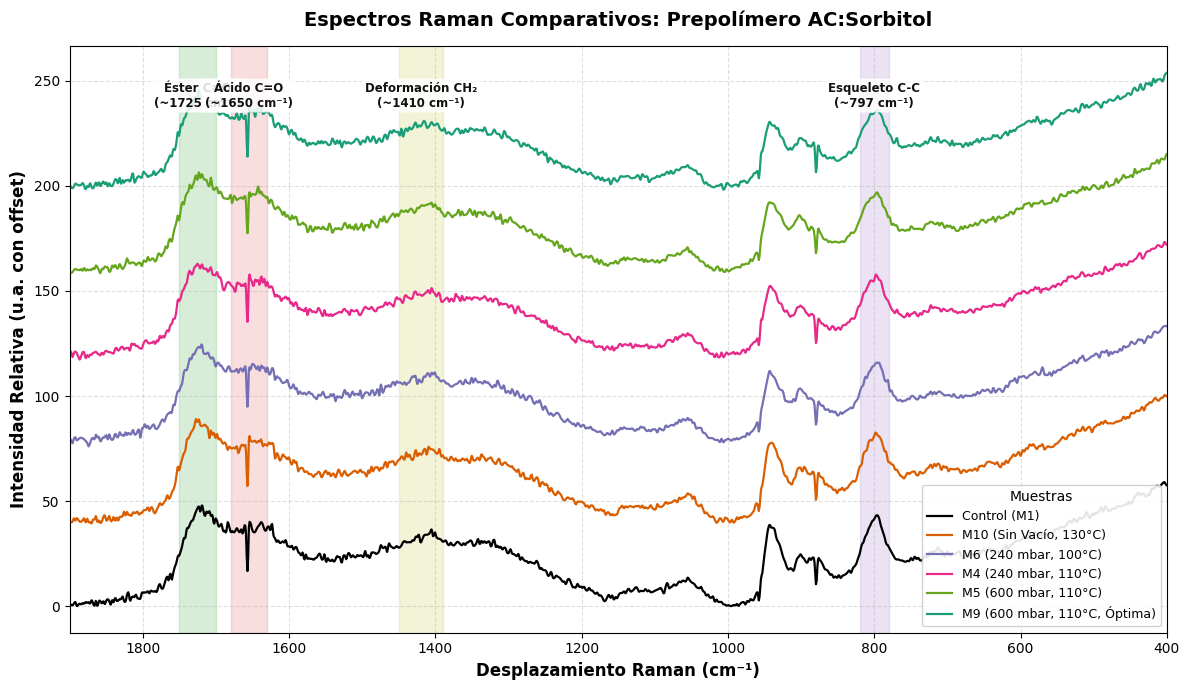

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

# 1. Definición de las franjas espectrales (x_min, x_max, color, opacidad, texto_etiqueta)
bands = [
    (1700, 1750, '#2ca02c', 0.18, 'Éster C=O\n(~1725 cm⁻¹)'),
    (1630, 1680, '#d62728', 0.15, 'Ácido C=O\n(~1650 cm⁻¹)'),
    (1390, 1450, '#bcbd22', 0.18, 'Deformación CH₂\n(~1410 cm⁻¹)'),
    (780, 820, '#9467bd', 0.18, 'Esqueleto C-C\n(~797 cm⁻¹)')
    ]

# 2. Trazar franjas y escribir el texto sobre cada una
for x_min, x_max, color, alpha, label_text in bands:
  ax.axvspan(x_min, x_max, color=color, alpha=alpha)
  x_center = (x_min + x_max) / 2

  # ax.get_xaxis_transform() fija la Y en porcentaje (0.94 = 94% de la altura del gráfico)
  ax.text(x_center, 0.94, label_text, transform=ax.get_xaxis_transform(),
          ha='center', va='top', fontsize=8.5, fontweight='bold', color='#111111',
          bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85, edgecolor='none'))

# 3. Cargar datos y graficar con desplazamiento vertical (offset)
offset_step = 40.0 # Ajusta la separación vertical entre curvas

for i, (fname, label_name, color_hex) in enumerate(samples):
  # Cargar CSV original
  df = pd.read_csv(fname, header=None, names=['shift', 'intensity'])
  # Filtrar rango de interés (400 a 1900 cm^-1)
  df_crop = df[(df['shift'] >= 400) & (df['shift'] <= 1900)].sort_values('shift')

  x = df_crop['shift'].values
  y = df_crop['intensity'].values + (i * offset_step)

  ax.plot(x, y, label=label_name, color=color_hex, linewidth=1.6)


# 4\. Configurar el eje X invertido (de 1900 a 400 cm⁻¹)
ax.set_xlim(1900, 400) # <-- Inversión del eje espectral
ax.set_xlabel('Desplazamiento Raman (cm⁻¹)', fontsize=12, fontweight='bold')
ax.set_ylabel('Intensidad Relativa (u.a. con offset)', fontsize=12, fontweight='bold')
ax.set_title('Espectros Raman Comparativos: Prepolímero AC:Sorbitol', fontsize=14, fontweight='bold', pad=15)

ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower right', frameon=True, fontsize=9, title='Muestras', facecolor='white', framealpha=0.9)

plt.tight_layout()
#plt.savefig('fig1\_espectros\_raman\_franjas.png', dpi=300)
plt.show()


##**Tabla**

In [14]:
import scipy.signal
import scipy.sparse
import scipy.sparse.linalg
import pandas as pd
import numpy as np

In [37]:
# Algoritmo ALS para correción de línea base
def baseline_als(y, lam=1e5, p=0.001, niter=10):
  L = len(y)
  # Matriz de segundas diferencias finitas
  D = scipy.sparse.diags([1, -2, 1], [0, 1, 2], shape=(L-2, L))
  w = np.ones(L)
  for i in range(niter):
    W = scipy.sparse.spdiags(w, 0, L, L)
    Z = W + lam * D.T.dot(D)
    Z = Z.tocsc()
    z = scipy.sparse.linalg.spsolve(Z, w * y)
    w = p * (y > z) + (1 - p) * (y <= z)
  return z

In [38]:
# Procesamiento espectral riguroso (Filtro SG + ALS + Normalización L2)
def process_spectrum(filepath):
  df = pd.read_csv(filepath, header=None, names=['shift', 'intensity'])
  df = df.sort_values('shift').reset_index(drop=True)

  # Suavizado y eliminación de fondo
  y_smooth = scipy.signal.savgol_filter(df['intensity'].values, window_length=15, polyorder=2)
  b = baseline_als(y_smooth)
  y_corr = y_smooth - b
  y_corr[y_corr < 0] = 0
  df['corr'] = y_corr

  # Normalización L2 en la región huella dactilar (400 - 1800 cm⁻¹)
  fp_mask = (df['shift'] >= 400) & (df['shift'] <= 1800)
  l2_norm = np.sqrt(np.sum(df.loc[fp_mask, 'corr']**2))
  df['norm'] = df['corr'] / (l2_norm if l2_norm > 0 else 1.0)

  # IER integración de picos / puntas máximas (~1725cm^-1 vs ~797 cm^-1)
  peak_ester = df.loc[(df['shift'] >= 1700) & (df['shift'] <= 1760), 'norm'].max()
  peak_ref = df.loc[(df['shift'] >= 770) & (df['shift'] <= 830), 'norm'].max()
  ier_picos = peak_ester / peak_ref if peak_ref > 0 else 0.0

  # IER integración de áreas (Éster vs Huella dactilar)
  area_ester = np.trapezoid(df.loc[(df['shift'] >= 1700) & (df['shift'] <= 1760), 'norm'],
                            df.loc[(df['shift'] >= 1700) & (df['shift'] <= 1760), 'shift'])
  area_fp = np.trapezoid(df.loc[(df['shift'] >= 700) & (df['shift'] <= 1500), 'norm'],
                         df.loc[(df['shift'] >= 700) & (df['shift'] <= 1500), 'shift'])
  ier_area = area_ester / area_fp if area_fp > 0 else 0.0

  return ier_picos, ier_area

In [44]:
# Definición de la metainformación de cada muestra
metadata = [
    {'sample': 'M1_A', 'file': 'A_M1.CSV', 'cat': 'Control', 'grade': 'Alimenticio', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M1_A', 'vac': np.nan, 'temp': np.nan, 'time': 0, 'vol':np.nan, 'rt': np.nan},
    {'sample': 'M2_A', 'file': 'A_M2.CSV', 'cat': 'Control', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': np.nan, 'temp': np.nan, 'time': 0, 'vol':np.nan, 'rt': np.nan},
    {'sample': 'M3', 'file': 'A_M3.CSV', 'cat': 'Muestra', 'grade': 'Alimenticio', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M1_A', 'vac': 240, 'temp': 110, 'time': 2, 'vol':500, 'rt': 0.828},
    {'sample': 'M4', 'file': 'A_M4.CSV', 'cat': 'Muestra', 'grade': 'Alimenticio', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M1_A', 'vac': 240, 'temp': 110, 'time': 4, 'vol':500, 'rt': 0.806},
    {'sample': 'M5', 'file': 'A_M5.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 600, 'temp': 110, 'time': 4, 'vol':500, 'rt': 0.753},
    {'sample': 'M6', 'file': 'A_M6.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 240, 'temp': 100, 'time': 4, 'vol':500, 'rt': 0.827},
    {'sample': 'M7', 'file': 'A_M7.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 240, 'temp': 110, 'time': 4, 'vol':1000, 'rt': 0.747},
    {'sample': 'M8', 'file': 'A_M8.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 600, 'temp': 130, 'time': 4, 'vol':1000, 'rt': 0.769},
    {'sample': 'M9', 'file': 'A_M9.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 600, 'temp': 110, 'time': 4, 'vol':500, 'rt': 0.775},
    {'sample': 'M10', 'file': 'A_M10.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'A', 'ctrl_used': 'M2_A', 'vac': 1015, 'temp': 130, 'time': 4, 'vol':500, 'rt': 0.836},
    {'sample': 'M1_B', 'file': 'B_M1.CSV', 'cat': 'Control', 'grade': 'Alimenticio', 'ratio': '5:1', 'day': 'B', 'ctrl_used': 'M1_B', 'vac': np.nan, 'temp': np.nan, 'time': 0, 'vol':np.nan, 'rt': np.nan},
    {'sample': 'M2_B', 'file': 'B_M2.CSV', 'cat': 'Control', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'B', 'ctrl_used': 'M2_B', 'vac': np.nan, 'temp': np.nan, 'time': 0, 'vol':np.nan, 'rt': np.nan},
    {'sample': 'M11', 'file': 'B_M11.CSV', 'cat': 'Muestra', 'grade': 'Alimenticio', 'ratio': '5:1', 'day': 'B', 'ctrl_used': 'M1_B', 'vac': 720, 'temp': 110, 'time': 4, 'vol':500, 'rt': np.nan},
    {'sample': 'M12', 'file': 'B_M12.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '5:1', 'day': 'B', 'ctrl_used': 'M2_B', 'vac': 1015, 'temp': 130, 'time': 4, 'vol':500, 'rt': 0.761},
    {'sample': 'M13', 'file': 'B_M13.CSV', 'cat': 'Control', 'grade': 'Analitico', 'ratio': '3:1', 'day': 'B', 'ctrl_used': 'M13', 'vac': np.nan, 'temp': np.nan, 'time': 0, 'vol':np.nan, 'rt': np.nan},
    {'sample': 'M14', 'file': 'B_M14.CSV', 'cat': 'Muestra', 'grade': 'Analitico', 'ratio': '3:1', 'day': 'B', 'ctrl_used': 'M13', 'vac': 240, 'temp': 110, 'time': 3, 'vol':1000, 'rt': 0.658}
    ]

In [45]:
# Procesar todas las muestras con spectrum
results = []
for item in metadata:
  ier_picos, ier_area = process_spectrum(item['file'])
  res = item.copy()
  res['IER_picos'] = ier_picos
  res['IER_area'] = ier_area
  results.append(res)

df_res = pd.DataFrame(results)

In [46]:
# Mapear el área del control asignado a cada fila
ctrl_dict = df_res[df_res['cat'] == 'Control'].set_index('sample')['IER_area'].to_dict()
df_res['ctrl_area'] = df_res['ctrl_used'].map(ctrl_dict)

# 5. Calcular la diferencia neta de área respecto a su blanco
df_res['delta_area'] = df_res['IER_area'] - df_res['ctrl_area']
df_res['delta_area'] = df_res['delta_area'].clip(lower=0.0)

# 6. Máximo Global Único para escalar al 100%
# Filtramos solo las filas que corresponden a "Muestra"
muestras_only = df_res[df_res['cat'] == 'Muestra']
# Obtenemos el índice de la muestra que logró la mayor delta_area
max_idx = muestras_only['delta_area'].idxmax()
max_delta_global = df_res.loc[max_idx, 'delta_area']
max_sample_name = df_res.loc[max_idx, 'sample']

# 7. Cálculo final de la Conversión a Éster (%)
df_res['alpha_ester_pct'] = (df_res['delta_area'] / max_delta_global) * 100.0
df_res.loc[df_res['cat'] == 'Control', 'alpha_ester_pct'] = 0.0

# Exportar tabla resumida a CSV
output_cols = ['sample', 'cat', 'ratio', 'day', 'ctrl_used', 'vac', 'temp', 'time', 'vol', 'rt', 'IER_picos', 'IER_area', 'alpha_ester_pct']
df_out = df_res[output_cols].copy()

df_out['IER_picos'] = df_out['IER_picos'].apply(lambda x: f"{x:.4f}" if pd.notnull(x) else "")
df_out['IER_area'] = df_out['IER_area'].apply(lambda x: f"{x:.4f}" if pd.notnull(x) else "")
df_out['alpha_ester_pct'] = df_out['alpha_ester_pct'].apply(lambda x: f"{x:.2f}%" if pd.notnull(x) else "")

#df_res[output_cols].to_csv('tabla_resultados_cuantitativos.csv', index=False)
print(df_out.to_string(index=False))

sample     cat ratio day ctrl_used    vac  temp  time    vol    rt IER_picos IER_area alpha_ester_pct
  M1_A Control   5:1   A      M1_A    NaN   NaN     0    NaN   NaN    1.3561   0.2539           0.00%
  M2_A Control   5:1   A      M2_A    NaN   NaN     0    NaN   NaN    1.3831   0.2638           0.00%
    M3 Muestra   5:1   A      M1_A  240.0 110.0     2  500.0 0.828    1.5755   0.2914          91.23%
    M4 Muestra   5:1   A      M1_A  240.0 110.0     4  500.0 0.806    1.4348   0.2940          97.58%
    M5 Muestra   5:1   A      M2_A  600.0 110.0     4  500.0 0.753    1.6154   0.3020          92.91%
    M6 Muestra   5:1   A      M2_A  240.0 100.0     4  500.0 0.827    1.5880   0.2894          62.30%
    M7 Muestra   5:1   A      M2_A  240.0 110.0     4 1000.0 0.747    1.5774   0.3003          88.70%
    M8 Muestra   5:1   A      M2_A  600.0 130.0     4 1000.0 0.769    1.5641   0.2831          47.04%
    M9 Muestra   5:1   A      M2_A  600.0 110.0     4  500.0 0.775    1.5794   0.3